# TSP Optimization with Simulated Annealing and Genetic Algorithms — Assignment Notebook

Works in **Jupyter** and **Google Colab**.

## Overview
You will solve the same TSP instance using **two heuristic optimization methods**:

1. **Simulated Annealing (SA)** with a 2-opt neighborhood  
2. **Genetic Algorithm (GA)** on **permutation tours** (a standard evolutionary approach for TSP)

The notebook provides:
- A reproducible TSP instance generator
- Tour utilities (length, validity)
- A 2-opt neighborhood operator
- Visualization helpers (tour plot + history plot)
- Baseline heuristic: nearest neighbor

## Tasks
### Task A — Simulated Annealing (SA)
Implement `simulated_annealing_tsp(...)`. Find sections with "TODO" to complete the implementations.

### Task B — Genetic Algorithm (GA)
Implement `genetic_algorithm_tsp(...)` plus helper functions:
- Tournament selection
- Order crossover (OX)
- Swap mutation
Find sections with "TODO" to complete the implementations.

## Deliverables
- Completed notebook (or exported `.py`) (find all TODOs and implement them)
- Write a technical report that includes:
  - Descriptions of the problem context, solutions (include important code snippets)
  - Experimental results, present the graphs, plots and data generated from the notebook based on your implementation.
    - SA parameters + best tour length
    - GA parameters + best tour length
    - Brief comparison: which worked better and why
    - More specifics can be found Part 6 below.
    - Optional work done in Part 7 below
  - Analysis of the experimental results.


---


In [1]:
# If running in a fresh environment, uncomment as needed:
# !pip -q install matplotlib numpy

import math
import os
import random
import statistics
from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt

# All figures are also saved here so they can be reused in the report.
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def _finish(save_as: Optional[str]) -> None:
    if save_as:
        plt.savefig(os.path.join(FIG_DIR, save_as), dpi=150, bbox_inches="tight")
    plt.show()


## Part 1 — TSP utilities (provided)

In [2]:
Point = Tuple[float, float]
Tour = List[int]

def make_cities(n: int = 40, seed: int = 7) -> List[Point]:
    # Reproducible 2D city coordinates in [0, 1]x[0, 1].
    rng = random.Random(seed)
    return [(rng.random(), rng.random()) for _ in range(n)]

def dist(a: Point, b: Point) -> float:
    dx = a[0] - b[0]
    dy = a[1] - b[1]
    return math.hypot(dx, dy)

def tour_length(cities: List[Point], tour: Tour) -> float:
    # Total length of a closed tour.
    n = len(tour)
    total = 0.0
    for i in range(n):
        total += dist(cities[tour[i]], cities[tour[(i + 1) % n]])
    return total

def is_valid_tour(tour: Tour, n: int) -> bool:
    return len(tour) == n and set(tour) == set(range(n))

def random_tour(n: int, rng: random.Random) -> Tour:
    t = list(range(n))
    rng.shuffle(t)
    return t

def nearest_neighbor_tour(cities: List[Point], start: int = 0) -> Tour:
    # Deterministic baseline: greedy nearest neighbor.
    n = len(cities)
    unvisited = set(range(n))
    tour = [start]
    unvisited.remove(start)
    cur = start
    while unvisited:
        nxt = min(unvisited, key=lambda j: dist(cities[cur], cities[j]))
        tour.append(nxt)
        unvisited.remove(nxt)
        cur = nxt
    return tour


## Part 2 — Neighborhood operator (2-opt) (provided)

In [3]:
def two_opt_swap(tour: Tour, i: int, k: int) -> Tour:
    # Return a new tour where the segment [i:k] is reversed.
    return tour[:i] + list(reversed(tour[i:k + 1])) + tour[k + 1:]

def random_two_opt_neighbor(tour: Tour, rng: random.Random) -> Tour:
    # Pick a random 2-opt move.
    n = len(tour)
    i = rng.randrange(0, n - 1)
    k = rng.randrange(i + 1, n)
    return two_opt_swap(tour, i, k)


## Part 3 — Visualization helpers (provided)

* You are encouraged to implement more variations of visualization.

In [4]:
def plot_tour(cities: List[Point], tour: Tour, title: str = "", save_as: Optional[str] = None) -> None:
    xs = [cities[i][0] for i in tour] + [cities[tour[0]][0]]
    ys = [cities[i][1] for i in tour] + [cities[tour[0]][1]]

    plt.figure(figsize=(6, 6))
    plt.plot(xs, ys, marker="o")
    plt.title(title)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.gca().set_aspect("equal", adjustable="box")
    _finish(save_as)

def plot_history(series: List[float], title: str, ylabel: str = "Value", save_as: Optional[str] = None,
                 xlabel: str = "Iteration") -> None:
    plt.figure(figsize=(7, 4))
    plt.plot(series)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    _finish(save_as)

def plot_compare(sa_hist: List[float], ga_hist: List[float], save_as: Optional[str] = None) -> None:
    # Overlay histories (x-axis is not identical meaning; this is a visual comparison).
    plt.figure(figsize=(8, 4))
    plt.plot(sa_hist, label="SA best-so-far")
    plt.plot([i * (len(sa_hist) / max(1, len(ga_hist)-1)) for i in range(len(ga_hist))], ga_hist, label="GA best-by-gen")
    plt.title("SA vs GA: Best tour length over time (scaled x-axis)")
    plt.xlabel("Progress (scaled)")
    plt.ylabel("Length")
    plt.legend()
    _finish(save_as)


## Part 4 — Baseline tour (nearest neighbor) (provided)

Nearest-neighbor length: 6.0214


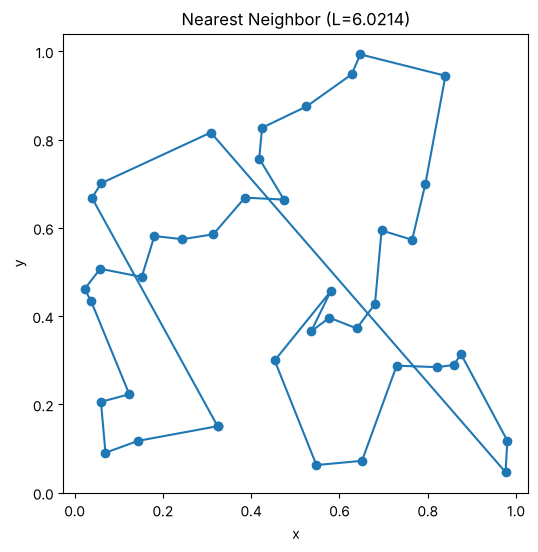

In [5]:
cities = make_cities(n=40, seed=7)

nn_tour = nearest_neighbor_tour(cities, start=0)
nn_len = tour_length(cities, nn_tour)
print(f"Nearest-neighbor length: {nn_len:.4f}")

plot_tour(cities, nn_tour, title=f"Nearest Neighbor (L={nn_len:.4f})", save_as="nn_tour.png")


# Part 5A — Code Skeleton: Simulated Annealing (SA)

Complete `simulated_annealing_tsp(...)`.

### SA acceptance rule
Let `delta = cand_len - cur_len`.
- If `delta <= 0`, accept.
- Else accept with probability `exp(-delta / T)`.

### Cooling schedule
Geometric cooling:
- `T = T * alpha` each iteration
- clamp `T = max(T, 1e-12)`


In [6]:
@dataclass
class SAConfig:
    iters: int = 20_000
    t0: float = 0.2
    alpha: float = 0.9995
    seed: int = 123
    report_every: int = 2000

def simulated_annealing_tsp(cities: List[Point], init_tour: Tour, cfg: SAConfig,
                            stats: Optional[Dict[str, list]] = None) -> Tuple[Tour, float, List[float]]:
    """Simulated annealing with a random 2-opt neighborhood and geometric cooling.

    If a dict is passed as `stats`, it is filled with per-iteration instrumentation
    (used in Part 6): accepted/rejected deltas, current length, temperature, etc.
    """
    rng = random.Random(cfg.seed)
    n = len(cities)
    assert is_valid_tour(init_tour, n), "init_tour must be a valid permutation"

    cur_tour = init_tour[:]
    cur_len = tour_length(cities, cur_tour)

    best_tour = cur_tour[:]
    best_len = cur_len
    history = [best_len]

    if stats is not None:
        stats.update(cur=[cur_len], temp=[cfg.t0], accepted_deltas=[], rejected_deltas=[],
                     uphill_accept_iters=[], improve_iters=[])

    T = cfg.t0

    for it in range(cfg.iters):
        cand_tour = random_two_opt_neighbor(cur_tour, rng)
        cand_len = tour_length(cities, cand_tour)
        delta = cand_len - cur_len

        # Acceptance rule (Metropolis criterion):
        #   delta <= 0 -> always accept (better or equal tour)
        #   delta >  0 -> accept with probability exp(-delta / T)
        if delta <= 0:
            accept = True
        else:
            accept = rng.random() < math.exp(-delta / T)

        if accept:
            cur_tour, cur_len = cand_tour, cand_len

        if cur_len < best_len:
            best_tour, best_len = cur_tour[:], cur_len
            if stats is not None:
                stats["improve_iters"].append(it + 1)

        history.append(best_len)

        if stats is not None:
            (stats["accepted_deltas"] if accept else stats["rejected_deltas"]).append(delta)
            if accept and delta > 0:
                stats["uphill_accept_iters"].append(it + 1)
            stats["cur"].append(cur_len)
            stats["temp"].append(T)

        # Cooling schedule: geometric decay, clamped to stay positive.
        T = max(T * cfg.alpha, 1e-12)

        if cfg.report_every and (it + 1) % cfg.report_every == 0:
            print(f"[SA] iter={it+1:6d}  T={T:.4g}  cur={cur_len:.4f}  best={best_len:.4f}")

    return best_tour, best_len, history


## Run SA (after you implement it)

[SA] iter=  2000  T=0.07356  cur=8.3800  best=6.0214
[SA] iter=  4000  T=0.02705  cur=6.5972  best=6.0214
[SA] iter=  6000  T=0.00995  cur=5.3139  best=5.3139
[SA] iter=  8000  T=0.003659  cur=5.0057  best=5.0057
[SA] iter= 10000  T=0.001346  cur=5.0057  best=5.0057
[SA] iter= 12000  T=0.000495  cur=5.0057  best=5.0057
[SA] iter= 14000  T=0.0001821  cur=5.0057  best=5.0057
[SA] iter= 16000  T=6.696e-05  cur=5.0057  best=5.0057
[SA] iter= 18000  T=2.463e-05  cur=5.0057  best=5.0057


[SA] iter= 20000  T=9.057e-06  cur=5.0057  best=5.0057
SA best length: 5.0057
SA improvement vs NN: 16.87%


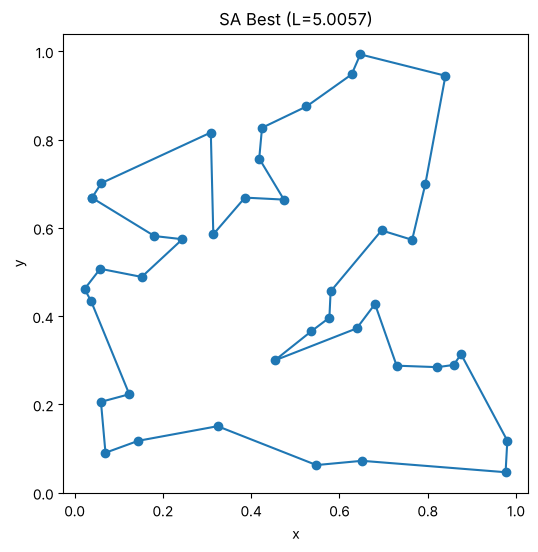

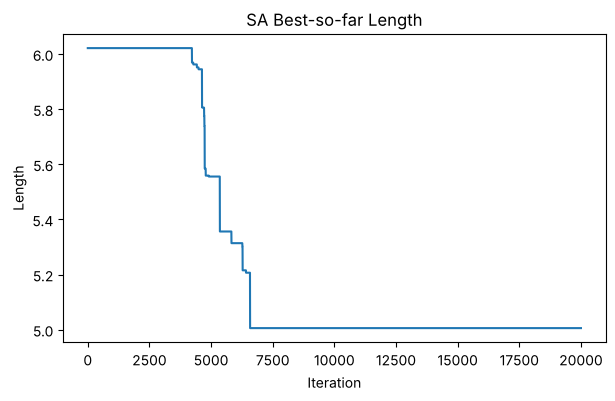

In [7]:
sa_cfg = SAConfig(iters=20_000, t0=0.2, alpha=0.9995, seed=123, report_every=2000)
sa_stats: Dict[str, list] = {}
sa_best_tour, sa_best_len, sa_hist = simulated_annealing_tsp(cities, nn_tour[:], sa_cfg, stats=sa_stats)

print(f"SA best length: {sa_best_len:.4f}")
print(f"SA improvement vs NN: {(nn_len - sa_best_len) / nn_len * 100:.2f}%")

assert is_valid_tour(sa_best_tour, len(cities))

plot_tour(cities, sa_best_tour, title=f"SA Best (L={sa_best_len:.4f})", save_as="sa_tour.png")
plot_history(sa_hist, title="SA Best-so-far Length", ylabel="Length", save_as="sa_history.png")


# Part 5B — Code Skeleton: Genetic Algorithm (GA) for TSP

Implement a GA that evolves a population of permutation tours.

You will implement:
- `tournament_select(...)`
- `order_crossover_ox(...)` (Order Crossover)
- `mutate_swap(...)`
- `genetic_algorithm_tsp(...)`


In [8]:
@dataclass
class GAConfig:
    pop_size: int = 200
    generations: int = 400
    tournament_k: int = 5
    crossover_rate: float = 0.9
    mutation_rate: float = 0.2
    elite_size: int = 5
    seed: int = 999
    report_every: int = 50

def tournament_select(pop: List[Tour], lengths: List[float], k: int, rng: random.Random) -> Tour:
    # Sample k distinct individuals uniformly; the shortest tour wins (we minimize length).
    contenders = rng.sample(range(len(pop)), k)
    winner = min(contenders, key=lambda i: lengths[i])
    return pop[winner][:]

def order_crossover_ox(parent1: Tour, parent2: Tour, rng: random.Random) -> Tour:
    # Order Crossover (OX):
    # 1. Copy a random slice [a, b] from parent1 into the child at the same positions.
    # 2. Fill the remaining positions, starting just after b and wrapping around,
    #    with parent2's cities in parent2's order (starting just after b), skipping
    #    cities already in the child. The result is always a valid permutation.
    n = len(parent1)
    a, b = sorted(rng.sample(range(n), 2))
    child: List[Optional[int]] = [None] * n
    child[a:b + 1] = parent1[a:b + 1]
    used = set(parent1[a:b + 1])

    fill_pos = (b + 1) % n
    for offset in range(n):
        city = parent2[(b + 1 + offset) % n]
        if city in used:
            continue
        child[fill_pos] = city
        used.add(city)
        fill_pos = (fill_pos + 1) % n
    return child  # type: ignore[return-value]

def mutate_swap(tour: Tour, rng: random.Random) -> Tour:
    # Swap mutation: exchange the cities at two distinct random positions.
    t = tour[:]
    i, j = rng.sample(range(len(t)), 2)
    t[i], t[j] = t[j], t[i]
    return t

def _edge_set(tour: Tour) -> set:
    n = len(tour)
    return {frozenset((tour[i], tour[(i + 1) % n])) for i in range(n)}

def genetic_algorithm_tsp(cities: List[Point], init_seed_tours: List[Tour], cfg: GAConfig,
                          stats: Optional[Dict[str, list]] = None) -> Tuple[Tour, float, List[float]]:
    """GA over permutation tours (tournament selection, OX, swap mutation, elitism).

    If a dict is passed as `stats`, per-generation population statistics are recorded
    (average / worst length, number of unique tours, edge diversity, evaluations).
    """
    rng = random.Random(cfg.seed)
    n = len(cities)

    pop: List[Tour] = []
    for t in init_seed_tours:
        assert is_valid_tour(t, n)
        pop.append(t[:])
    while len(pop) < cfg.pop_size:
        pop.append(random_tour(n, rng))

    lengths = [tour_length(cities, t) for t in pop]
    evals = len(pop)
    best_idx = min(range(len(pop)), key=lambda i: lengths[i])
    best_tour = pop[best_idx][:]
    best_len = lengths[best_idx]
    history = [best_len]

    def record() -> None:
        if stats is None:
            return
        gb = min(range(len(pop)), key=lambda i: lengths[i])
        best_edges = _edge_set(pop[gb])
        # Edge diversity: mean fraction of edges an individual does NOT share with the current best.
        edge_div = statistics.mean(1 - len(_edge_set(t) & best_edges) / n for t in pop)
        stats.setdefault("avg", []).append(statistics.mean(lengths))
        stats.setdefault("worst", []).append(max(lengths))
        stats.setdefault("std", []).append(statistics.pstdev(lengths))
        stats.setdefault("unique", []).append(len({tuple(t) for t in pop}))
        stats.setdefault("edge_div", []).append(edge_div)
        stats.setdefault("evals", []).append(evals)

    record()

    for gen in range(cfg.generations):
        elite_indices = sorted(range(len(pop)), key=lambda i: lengths[i])[: cfg.elite_size]
        next_pop = [pop[i][:] for i in elite_indices]

        while len(next_pop) < cfg.pop_size:
            p1 = tournament_select(pop, lengths, cfg.tournament_k, rng)
            p2 = tournament_select(pop, lengths, cfg.tournament_k, rng)

            if rng.random() < cfg.crossover_rate:
                child = order_crossover_ox(p1, p2, rng)
            else:
                child = p1[:]

            if rng.random() < cfg.mutation_rate:
                child = mutate_swap(child, rng)

            next_pop.append(child)

        pop = next_pop
        lengths = [tour_length(cities, t) for t in pop]
        evals += len(pop)

        gen_best_idx = min(range(len(pop)), key=lambda i: lengths[i])
        gen_best_len = lengths[gen_best_idx]
        if gen_best_len < best_len:
            best_len = gen_best_len
            best_tour = pop[gen_best_idx][:]

        history.append(best_len)
        record()

        if cfg.report_every and (gen + 1) % cfg.report_every == 0:
            print(f"[GA] gen={gen+1:4d}  best={best_len:.4f}")

    assert is_valid_tour(best_tour, n)
    return best_tour, best_len, history


In [9]:
# Sanity checks for the GA operators.
_rng = random.Random(0)
for _ in range(1000):
    a, b = random_tour(10, _rng), random_tour(10, _rng)
    assert is_valid_tour(order_crossover_ox(a, b, _rng), 10)
    m = mutate_swap(a, _rng)
    assert is_valid_tour(m, 10) and sum(x != y for x, y in zip(a, m)) == 2
_lens = [5.0, 1.0, 3.0, 2.0]
assert tournament_select([[0], [1], [2], [3]], _lens, k=4, rng=_rng) == [1]  # full tournament -> best
print("GA operator checks passed.")


GA operator checks passed.


## Run GA

* After you implement TODOs above
* This is just for your reference, you can experiment with different paramesters

[GA] gen=  50  best=5.3672


[GA] gen= 100  best=5.3672


[GA] gen= 150  best=5.3672


[GA] gen= 200  best=5.3672


[GA] gen= 250  best=5.3672


[GA] gen= 300  best=5.3672


[GA] gen= 350  best=5.3672


[GA] gen= 400  best=5.3672
GA best length: 5.3672
GA improvement vs NN: 10.86%


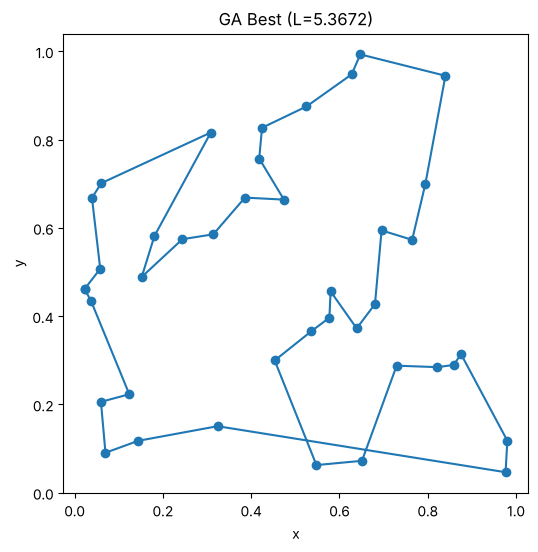

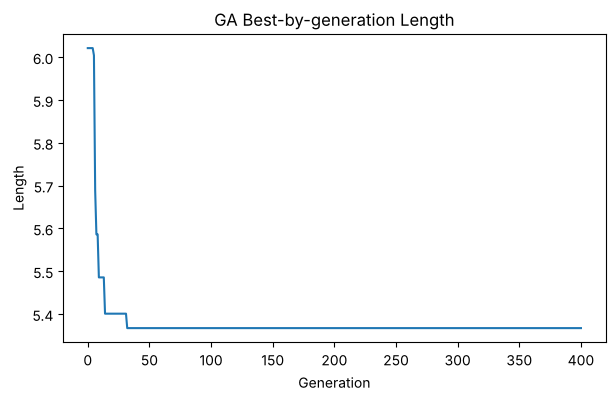

In [10]:
ga_cfg = GAConfig(pop_size=200, generations=400, tournament_k=5, crossover_rate=0.9,
                   mutation_rate=0.2, elite_size=5, seed=999, report_every=50)

ga_stats: Dict[str, list] = {}
ga_best_tour, ga_best_len, ga_hist = genetic_algorithm_tsp(cities, init_seed_tours=[nn_tour], cfg=ga_cfg, stats=ga_stats)

print(f"GA best length: {ga_best_len:.4f}")
print(f"GA improvement vs NN: {(nn_len - ga_best_len) / nn_len * 100:.2f}%")

plot_tour(cities, ga_best_tour, title=f"GA Best (L={ga_best_len:.4f})", save_as="ga_tour.png")
plot_history(ga_hist, title="GA Best-by-generation Length", ylabel="Length", save_as="ga_history.png",
             xlabel="Generation")


# Part 6 — Data Collection, Visualization and Comparison

* Instrument the code to collect the data and visualize them, including but not limited to
  * SA:
    * Track histogram of ΔE values for: Accepted moves and Rejected moves
  * GA:
    * Population average fitness
  * Cross SA and GA:
    * Plot SA best-so-far curve
    * Plot GA best-by-generation curve
    * Normalize x-axis by total evaluations
    * The above is already provided in the skeleton code. **Use them and/or with additional instrumentation of the code to collect and/or plot more data** to answer the following questions:
      * Which algorithm converged faster?
      * Which showed more variability?
      * Did SA escape local minima? Evidence?
      * Did GA lose diversity? Evidence?
* You are encouraged to come up with your own visualization and compare these two methods more extensively.

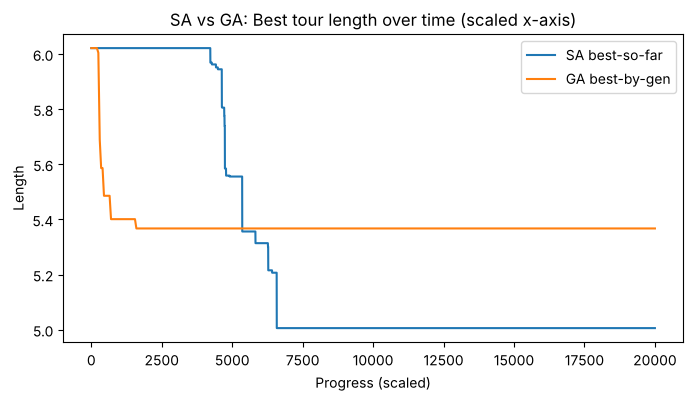

NN: 6.0214 | SA: 5.0057 | GA: 5.3672


In [11]:
plot_compare(sa_hist, ga_hist, save_as="compare_scaled.png")
print(f"NN: {nn_len:.4f} | SA: {sa_best_len:.4f} | GA: {ga_best_len:.4f}")


## 6.1 SA — ΔE histograms for accepted vs. rejected moves

Total moves: 20000 | accepted: 608 | rejected: 19392
Accepted improving/neutral (ΔE<=0): 325 | accepted uphill (ΔE>0): 283
Largest accepted uphill ΔE: 1.1310


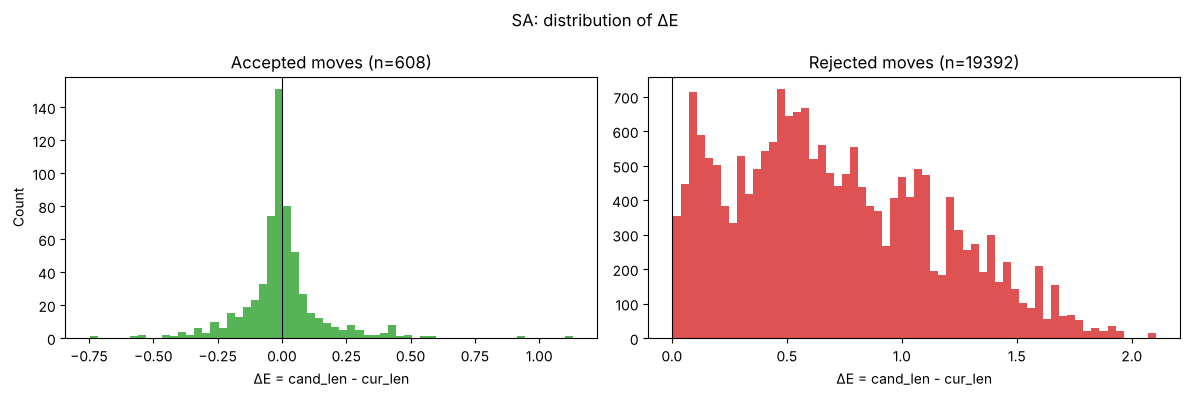

Uphill acceptances by phase:
  early (T high) : 272
  middle         : 6
  late (T low)   : 5


In [12]:
acc = sa_stats["accepted_deltas"]
rej = sa_stats["rejected_deltas"]
acc_up = [d for d in acc if d > 0]
print(f"Total moves: {len(acc) + len(rej)} | accepted: {len(acc)} | rejected: {len(rej)}")
print(f"Accepted improving/neutral (ΔE<=0): {len(acc) - len(acc_up)} | accepted uphill (ΔE>0): {len(acc_up)}")
print(f"Largest accepted uphill ΔE: {max(acc_up):.4f}" if acc_up else "No uphill moves accepted")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = 60
axes[0].hist(acc, bins=bins, color="tab:green", alpha=0.8)
axes[0].set_title(f"Accepted moves (n={len(acc)})")
axes[0].set_xlabel("ΔE = cand_len - cur_len"); axes[0].set_ylabel("Count")
axes[0].axvline(0, color="k", lw=0.8)
axes[1].hist(rej, bins=bins, color="tab:red", alpha=0.8)
axes[1].set_title(f"Rejected moves (n={len(rej)})")
axes[1].set_xlabel("ΔE = cand_len - cur_len")
axes[1].axvline(0, color="k", lw=0.8)
plt.suptitle("SA: distribution of ΔE")
plt.tight_layout()
_finish("sa_delta_hist.png")

# Zoom on uphill accepted moves, split by run phase
third = sa_cfg.iters // 3
phases = [("early (T high)", 0, third), ("middle", third, 2 * third), ("late (T low)", 2 * third, sa_cfg.iters)]
up_iters = sa_stats["uphill_accept_iters"]
print("Uphill acceptances by phase:")
for name, lo, hi in phases:
    cnt = sum(lo < i <= hi for i in up_iters)
    print(f"  {name:15s}: {cnt}")


## 6.2 SA — current vs. best-so-far length and temperature

The current tour (blue) rising above the best-so-far (orange) shows SA accepting worse tours; best-so-far improvements that come *after* such climbs are evidence of escaping local minima.

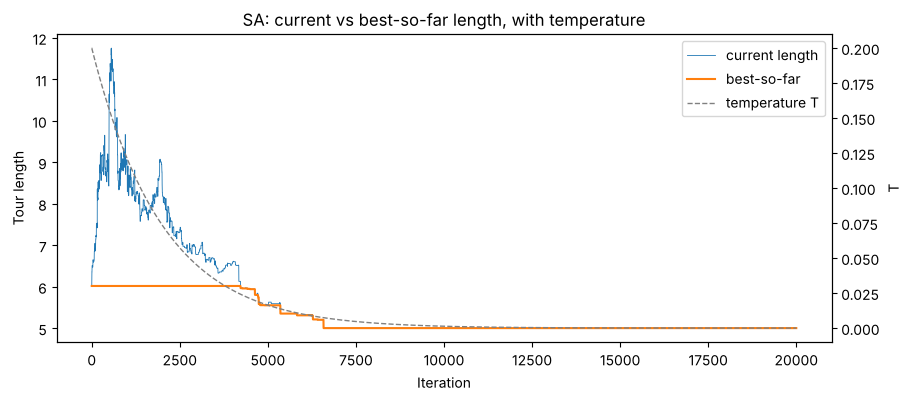

Best-so-far improvements: 20
...of which preceded by an uphill excursion above the incumbent best: 7
Largest climb above incumbent before a new best was found: 5.7341
Last best-so-far improvement at iteration: 6623


In [13]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(sa_stats["cur"], lw=0.6, label="current length", color="tab:blue")
ax1.plot(sa_hist, lw=1.5, label="best-so-far", color="tab:orange")
ax1.set_xlabel("Iteration"); ax1.set_ylabel("Tour length")
ax2 = ax1.twinx()
ax2.plot(sa_stats["temp"], color="gray", ls="--", lw=1, label="temperature T")
ax2.set_ylabel("T")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
plt.title("SA: current vs best-so-far length, with temperature")
_finish("sa_current_vs_best.png")

# Evidence of escaping local minima: best-so-far improvements that happened while
# the current tour had previously moved uphill (i.e., SA left a basin and found a better one).
cur = sa_stats["cur"]
escapes = 0
gaps = []
for it in sa_stats["improve_iters"]:
    prev_best = sa_hist[it - 1]
    # look back: was the current tour ever above prev_best since prev_best was set?
    j = it - 1
    while j > 0 and sa_hist[j - 1] == prev_best:
        j -= 1
    peak = max(cur[j:it]) if it > j else prev_best
    if peak > prev_best + 1e-12:
        escapes += 1
        gaps.append(peak - prev_best)
print(f"Best-so-far improvements: {len(sa_stats['improve_iters'])}")
print(f"...of which preceded by an uphill excursion above the incumbent best: {escapes}")
if gaps:
    print(f"Largest climb above incumbent before a new best was found: {max(gaps):.4f}")
print(f"Last best-so-far improvement at iteration: {sa_stats['improve_iters'][-1] if sa_stats['improve_iters'] else 'n/a'}")


## 6.3 GA — population average fitness and diversity

Fitness = −(tour length), so we plot length directly (lower is better). Diversity is measured two ways: the number of **unique tours** in the population, and **edge diversity** = mean fraction of an individual's edges not shared with the current best tour (0 means every individual uses the best tour's edges).

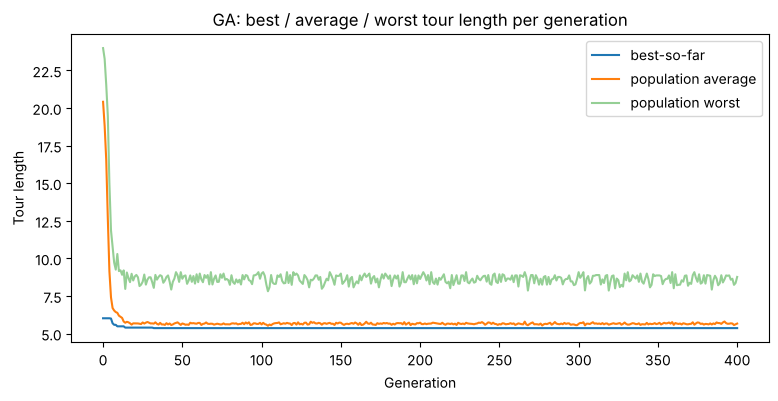

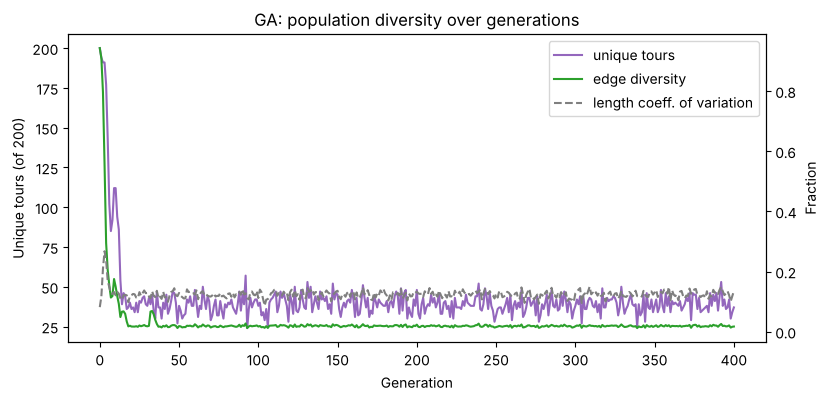

gen   0: best=6.0214 avg=20.4165 unique=200 edge_div=0.943
gen  25: best=5.4010 avg=5.7427 unique= 41 edge_div=0.020
gen  50: best=5.3672 avg=5.6735 unique= 38 edge_div=0.018
gen 100: best=5.3672 avg=5.6110 unique= 38 edge_div=0.017
gen 200: best=5.3672 avg=5.7282 unique= 48 edge_div=0.023
gen 400: best=5.3672 avg=5.6688 unique= 37 edge_div=0.017
Last GA best improvement at generation 32


In [14]:
gens = range(len(ga_hist))
plt.figure(figsize=(9, 4))
plt.plot(gens, ga_hist, label="best-so-far")
plt.plot(gens, ga_stats["avg"], label="population average")
plt.plot(gens, ga_stats["worst"], label="population worst", alpha=0.5)
plt.xlabel("Generation"); plt.ylabel("Tour length"); plt.legend()
plt.title("GA: best / average / worst tour length per generation")
_finish("ga_avg_fitness.png")

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(gens, ga_stats["unique"], color="tab:purple", label="unique tours")
ax1.set_xlabel("Generation"); ax1.set_ylabel(f"Unique tours (of {ga_cfg.pop_size})")
ax2 = ax1.twinx()
ax2.plot(gens, ga_stats["edge_div"], color="tab:green", label="edge diversity")
ax2.plot(gens, [s / a for s, a in zip(ga_stats["std"], ga_stats["avg"])], color="tab:gray", ls="--",
         label="length coeff. of variation")
ax2.set_ylabel("Fraction")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
plt.title("GA: population diversity over generations")
_finish("ga_diversity.png")

for g in [0, 25, 50, 100, 200, 400]:
    if g < len(ga_hist):
        print(f"gen {g:3d}: best={ga_hist[g]:.4f} avg={ga_stats['avg'][g]:.4f} "
              f"unique={ga_stats['unique'][g]:3d} edge_div={ga_stats['edge_div'][g]:.3f}")
last_imp = max(i for i in range(1, len(ga_hist)) if ga_hist[i] < ga_hist[i - 1]) if any(
    ga_hist[i] < ga_hist[i - 1] for i in range(1, len(ga_hist))) else 0
print(f"Last GA best improvement at generation {last_imp}")


## 6.4 Cross comparison — x-axis normalized by total tour evaluations

SA performs 1 tour evaluation per iteration; the GA evaluates its whole population each generation (200 per generation plus 200 for the initial population). Plotting against evaluations gives a fair "cost" axis.

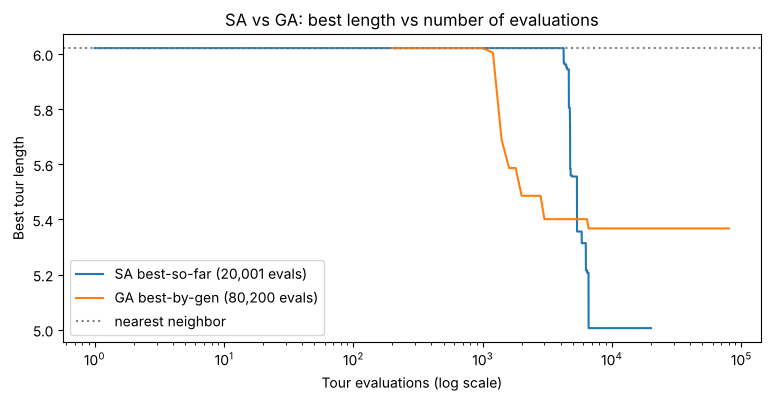

SA: final=5.0057, evals to reach within 1% of own final = 6,580, evals to beat SA final = 6624
GA: final=5.3672, evals to reach within 1% of own final = 3,000, evals to beat SA final = None


In [15]:
sa_evals = list(range(1, len(sa_hist) + 1))           # initial tour + one per iteration
ga_evals = ga_stats["evals"]                            # cumulative evaluations per generation

plt.figure(figsize=(9, 4))
plt.plot(sa_evals, sa_hist, label=f"SA best-so-far ({sa_evals[-1]:,} evals)")
plt.plot(ga_evals, ga_hist, label=f"GA best-by-gen ({ga_evals[-1]:,} evals)")
plt.axhline(nn_len, color="gray", ls=":", label="nearest neighbor")
plt.xscale("log")
plt.xlabel("Tour evaluations (log scale)"); plt.ylabel("Best tour length")
plt.title("SA vs GA: best length vs number of evaluations")
plt.legend()
_finish("compare_evals.png")

def evals_to_within(hist, evals, final, tol=0.01):
    target = final * (1 + tol)
    for h, e in zip(hist, evals):
        if h <= target:
            return e
    return None

for name, h, e in [("SA", sa_hist, sa_evals), ("GA", ga_hist, ga_evals)]:
    print(f"{name}: final={h[-1]:.4f}, evals to reach within 1% of own final = {evals_to_within(h, e, h[-1]):,}, "
          f"evals to beat SA final = {evals_to_within(h, e, sa_hist[-1], 0.0)}")


## 6.5 Variability across random seeds

A single run says little about variability, so both algorithms are run with 10 different seeds on the same instance. Because the default GA uses 4× more evaluations than SA (80,200 vs 20,001), an **equal-budget GA** (pop 100 × 199 generations ≈ 20,000 evaluations) is also included.

Method                               mean      std      min      max  mean impr. vs NN
SA                                 4.9571   0.1139   4.8339   5.1192            17.68%
GA (default, 80k evals)            5.5624   0.3604   5.1546   5.9001             7.62%
GA (equal budget, 20k evals)       5.7553   0.2378   5.3245   5.9001             4.42%


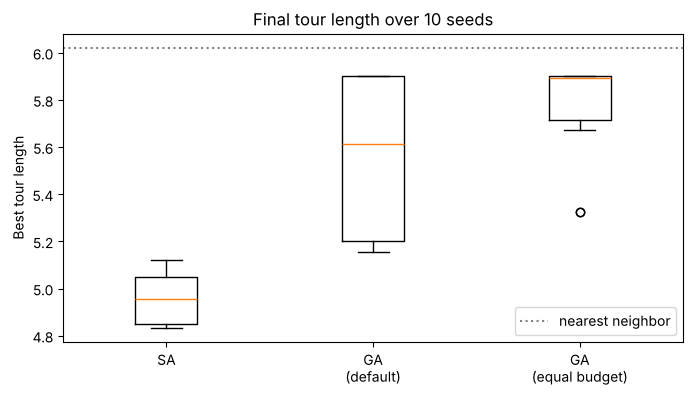

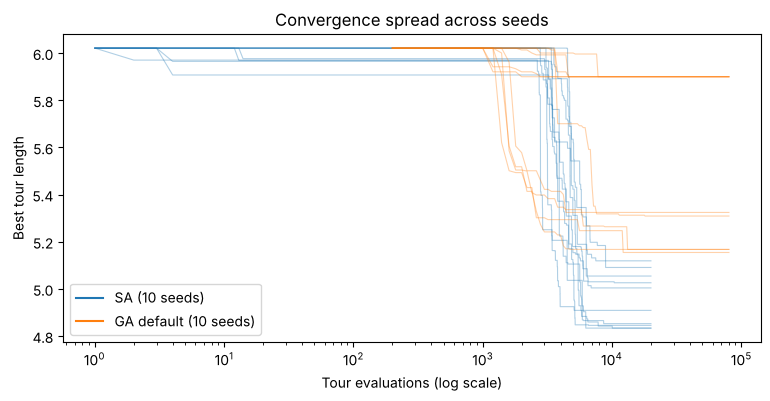

In [16]:
SEEDS = list(range(10))
results = {"SA": [], "GA (default, 80k evals)": [], "GA (equal budget, 20k evals)": []}
curves = {k: [] for k in results}

for s in SEEDS:
    _, l, h = simulated_annealing_tsp(cities, nn_tour[:], SAConfig(seed=s, report_every=0))
    results["SA"].append(l); curves["SA"].append(h)

    st = {}
    _, l, h = genetic_algorithm_tsp(cities, [nn_tour], GAConfig(seed=s, report_every=0), stats=st)
    results["GA (default, 80k evals)"].append(l); curves["GA (default, 80k evals)"].append((st["evals"], h))

    st = {}
    _, l, h = genetic_algorithm_tsp(cities, [nn_tour], GAConfig(pop_size=100, generations=199, seed=s, report_every=0), stats=st)
    results["GA (equal budget, 20k evals)"].append(l); curves["GA (equal budget, 20k evals)"].append((st["evals"], h))

print(f"{'Method':32s} {'mean':>8s} {'std':>8s} {'min':>8s} {'max':>8s} {'mean impr. vs NN':>17s}")
for k, v in results.items():
    print(f"{k:32s} {statistics.mean(v):8.4f} {statistics.stdev(v):8.4f} {min(v):8.4f} {max(v):8.4f} "
          f"{(nn_len - statistics.mean(v)) / nn_len * 100:16.2f}%")

plt.figure(figsize=(8, 4))
plt.boxplot(list(results.values()))
plt.xticks([1, 2, 3], ["SA", "GA\n(default)", "GA\n(equal budget)"])
plt.axhline(nn_len, color="gray", ls=":", label="nearest neighbor")
plt.ylabel("Best tour length"); plt.title("Final tour length over 10 seeds")
plt.legend()
_finish("seed_boxplot.png")

plt.figure(figsize=(9, 4))
for h in curves["SA"]:
    plt.plot(range(1, len(h) + 1), h, color="tab:blue", alpha=0.35, lw=0.8)
for e, h in curves["GA (default, 80k evals)"]:
    plt.plot(e, h, color="tab:orange", alpha=0.35, lw=0.8)
plt.plot([], [], color="tab:blue", label="SA (10 seeds)")
plt.plot([], [], color="tab:orange", label="GA default (10 seeds)")
plt.xscale("log"); plt.xlabel("Tour evaluations (log scale)"); plt.ylabel("Best tour length")
plt.title("Convergence spread across seeds")
plt.legend()
_finish("seed_curves.png")


## 6.6 Final summary and grade check

NN: 6.0214 | SA: 5.0057 | GA: 5.3672


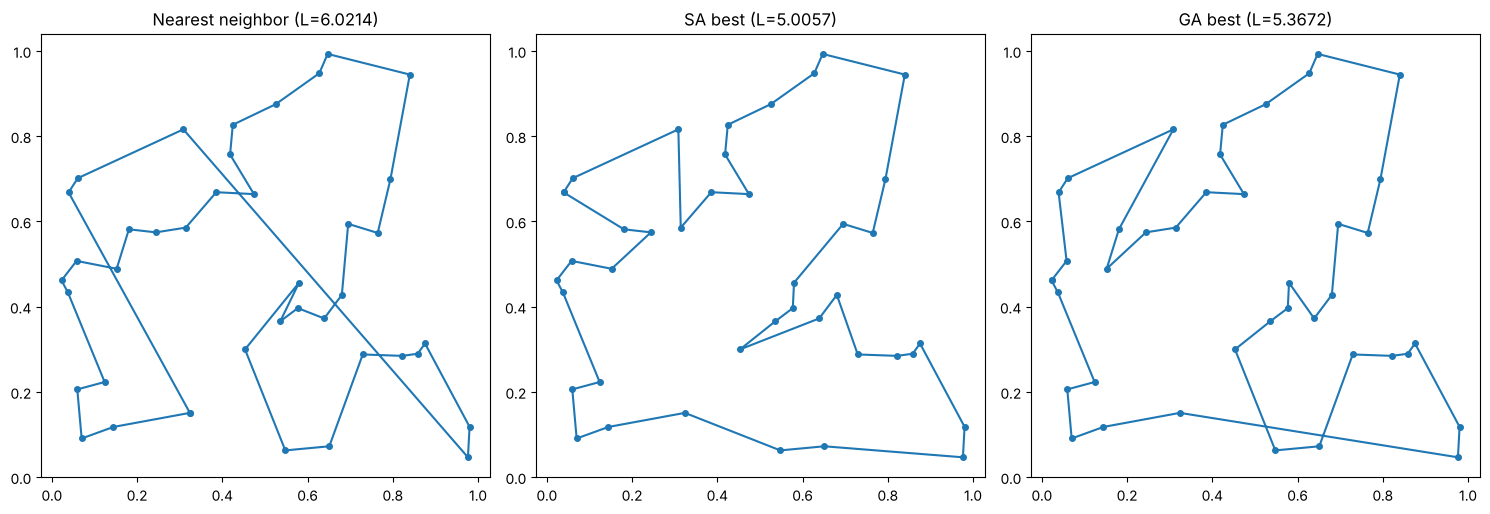

In [17]:
print(f"NN: {nn_len:.4f} | SA: {sa_best_len:.4f} | GA: {ga_best_len:.4f}")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, t, L) in zip(axes, [("Nearest neighbor", nn_tour, nn_len), ("SA best", sa_best_tour, sa_best_len),
                                   ("GA best", ga_best_tour, ga_best_len)]):
    xs = [cities[i][0] for i in t] + [cities[t[0]][0]]
    ys = [cities[i][1] for i in t] + [cities[t[0]][1]]
    ax.plot(xs, ys, marker="o", ms=4)
    ax.set_title(f"{name} (L={L:.4f})"); ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
_finish("tours_side_by_side.png")


## 6.7 Extra analytic — are the final tours 2-opt local optima?

For each final tour we count how many of the 780 possible 2-opt moves would still shorten it. Zero means the tour is a 2-opt local optimum (no crossing edges left to untangle).

In [18]:
def count_improving_two_opt(cities, tour):
    n, L, cnt = len(tour), tour_length(cities, tour), 0
    for i in range(n - 1):
        for k in range(i + 1, n):
            if tour_length(cities, two_opt_swap(tour, i, k)) < L - 1e-12:
                cnt += 1
    return cnt

for name, t in [("Nearest neighbor", nn_tour), ("SA best", sa_best_tour), ("GA best", ga_best_tour)]:
    print(f"{name:17s}: {count_improving_two_opt(cities, t):3d} improving 2-opt moves remain")


Nearest neighbor :  30 improving 2-opt moves remain
SA best          :   0 improving 2-opt moves remain
GA best          :   3 improving 2-opt moves remain


## 6.8 Answers to the Part 6 questions

Numbers below come from the outputs above (instance: 40 cities, seed 7; NN baseline 6.0214).

| Method | Parameters | Best length (main run) | Improvement vs NN | Mean ± std over 10 seeds |
|---|---|---|---|---|
| SA | iters=20,000, T0=0.2, α=0.9995, 2-opt neighbor, start = NN tour | 5.0057 | 16.87% | 4.957 ± 0.114 |
| GA | pop=200, gens=400, k=5, Pc=0.9, Pm=0.2, elite=5, OX + swap, NN seeded | 5.3672 | 10.86% | 5.562 ± 0.360 |
| GA (equal budget) | pop=100, gens=199 (≈20k evals) | — | — | 5.755 ± 0.238 |

**Which algorithm converged faster?** It depends on what "converged" means, and the distinction is the main finding. The GA *stopped improving* sooner: it was within 1% of its own final value after about 3,000 evaluations and made its last improvement at generation 32. SA needed about 6,600 evaluations to settle. But the GA converged prematurely to a worse tour (5.367), while SA kept improving to 5.006 and passed the GA's final value well before it settled. Per unit of quality, SA was faster: the GA never reached SA's result in 80,200 evaluations, four times SA's budget.

**Which showed more variability?** Across seeds, the GA: its final lengths have a standard deviation of 0.360 (range 5.15–5.90) against 0.114 for SA (range 4.83–5.12). Several GA runs barely improved on the nearest-neighbor tour, because the population collapsed onto the NN seed before useful structure was found. Within a single run, SA's *current* tour is the noisiest signal (it climbs from 6.0 to about 11.7 at high temperature), but that noise is deliberate exploration, and its final outcome is consistent.

**Did SA escape local minima? Evidence?** Yes. 
1. The ΔE histogram shows 283 accepted uphill moves (largest ΔE = 1.13), 272 of them in the first third of the run when T is high. A hill-climber would accept none.
2. The nearest-neighbor start is not a deep minimum, but SA did not just polish it: the current-vs-best plot shows SA leaving the NN basin entirely, then cooling into a different and better region. 7 of the 20 best-so-far improvements came after the current tour had climbed above the incumbent best.
3. SA's final tour has 0 improving 2-opt moves left (the NN tour had 30), so it ended in a genuine 2-opt local optimum that is 16.9% shorter than the start. After about iteration 6,600 the temperature is too low to accept uphill moves (only 5 in the last third), so the run is effectively frozen in that minimum.

**Did GA lose diversity? Evidence?** Yes, quickly and almost completely. 
1. The number of unique tours fell from 200 to 41 by generation 25 and hovered around 25–50 for the rest of the run.
2. Edge diversity fell from 0.94 to about 0.02, so on average 98% of every individual's edges match the best tour. The population is essentially copies of one tour plus small swap mutations.
3. The best/average gap closed to a small constant, and the best length never changed after generation 32 even though 368 generations remained.
4. The GA's best tour still has 3 improving 2-opt moves (a visible edge crossing), which shows the population was stuck: OX on near-identical parents reproduces the parent, and a single random swap usually breaks two good edges, so it rarely fixes a crossing.

The causes are strong selection pressure (tournament k=5 plus elitism), a single strong NN seed that dominates a random initial population (lengths ≈ 20), and swap mutation, which is a poor fit for TSP's edge structure.

**Which worked better and why?** SA was better on every measure here: better best tour, better average, lower variance, and a quarter of the evaluations. The 2-opt move matches the TSP well (it changes exactly two edges and directly removes crossings), and the annealing schedule supplies controlled exploration early. The GA as configured explores widely only at the very start, then loses diversity and depends on a mutation operator that does not respect tour structure.


## Example of how to check your work

In [19]:
def grade_check(nn_len: float, method_len: float, min_improvement_pct: float = 10.0, label: str = "Method") -> None:
    improvement = (nn_len - method_len) / nn_len * 100.0
    print(f"{label} length: {method_len:.4f} | Improvement vs NN: {improvement:.2f}%")
    assert improvement >= min_improvement_pct, (
        f"{label} improvement {improvement:.2f}% is below required {min_improvement_pct:.2f}%"
    )
    print(f"✅ {label} passed improvement threshold!")


In [20]:
grade_check(nn_len, sa_best_len, label="SA")
grade_check(nn_len, ga_best_len, label="GA")


SA length: 5.0057 | Improvement vs NN: 16.87%
✅ SA passed improvement threshold!
GA length: 5.3672 | Improvement vs NN: 10.86%
✅ GA passed improvement threshold!


# Part 7: Optional Task

The optional extra work will be considered for extra credit.

- Try different crossover and/or mutation operations in GA and see if you can improve the performance.

- If you identify other interesting analytics of intermediate data that shows how the algorithms are performing, you can carry out the experiements in this section.

- Document your effort in this section **and** the technical report mentioned above in the Deliverables.


_Not attempted in this submission._
